# Esteira de aprendizado de máquina — risco de consumo de cannabis

**Base:** [Drug Consumption (Quantified)](https://archive.ics.uci.edu/dataset/373/drug+consumption+quantified) — UCI, id `373`.

**Problema:** classificação binária — prever se a pessoa é **usuária de cannabis** (uso na última década ou mais recente) a partir de dados demográficos e do modelo dos Cinco Fatores de personalidade (NEO-FFI-R, impulsividade e busca de sensação).

**Recorte profissional:** o mesmo desenho aparece em saúde pública, psicologia e avaliação de risco. O artigo original (Fehrman et al., 2015) trata exatamente dessa binarização por substância.

A carga usa `ucimlrepo`. Se não houver internet, o notebook lê o ZIP local `drug+consumption+quantified.zip`.

Etapas: estatísticas descritivas → transformação em colunas → transformação em linhas → treino / validação / teste → modelo → matriz de confusão e acurácia → predição com o modelo implantado.

## 0. Ambiente

In [18]:
# Execute uma vez se as bibliotecas ainda não estiverem instaladas.
# %pip install pandas numpy matplotlib seaborn scikit-learn joblib ucimlrepo

In [19]:
from pathlib import Path
import json
import warnings
import zipfile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from ucimlrepo import fetch_ucirepo

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

RAIZ = Path.cwd()
PASTA_ARTEFATOS = RAIZ / "artefatos"
PASTA_ARTEFATOS.mkdir(exist_ok=True)
CAMINHO_ZIP = RAIZ / "drug+consumption+quantified.zip"

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1. Carga da base (UCI id=373)

Primeiro o pacote oficial; se falhar, o arquivo `.data` dentro do ZIP da UCI.

In [20]:
COLUNAS_ARQUIVO = [
    "id", "age", "gender", "education", "country", "ethnicity",
    "nscore", "escore", "oscore", "ascore", "cscore", "impulsive", "ss",
    "alcohol", "amphet", "amyl", "benzos", "caff", "cannabis", "choc", "coke",
    "crack", "ecstasy", "heroin", "ketamine", "legalh", "lsd", "meth",
    "mushrooms", "nicotine", "semer", "vsa",
]

ALVO_SUBSTANCIA = "cannabis"


def _normalizar_colunas(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = (
        df.columns.str.strip()
        .str.lower()
        .str.replace(r"[^a-z0-9]+", "", regex=True)
    )
    df = df.rename(columns={"impuslive": "impulsive"})
    return df


def carregar_via_zip() -> pd.DataFrame:
    with zipfile.ZipFile(CAMINHO_ZIP) as zf:
        nome = next(n for n in zf.namelist() if n.endswith(".data") or n.endswith(".csv"))
        with zf.open(nome) as fh:
            df_zip = pd.read_csv(fh, header=None, names=COLUNAS_ARQUIVO)
    print(f"Lido do ZIP local: {CAMINHO_ZIP.name} ({nome})")
    return df_zip


def carregar_base() -> pd.DataFrame:
    try:
        drug_consumption_quantified = fetch_ucirepo(id=373)
        X = drug_consumption_quantified.data.features
        y = drug_consumption_quantified.data.targets
        ids = getattr(drug_consumption_quantified.data, "ids", None)
        partes = [p for p in (ids, X, y) if p is not None]
        df_remoto = pd.concat(partes, axis=1)
        print("Base carregada via ucimlrepo (id=373).")
        print(drug_consumption_quantified.metadata)
        display(drug_consumption_quantified.variables)
        return df_remoto
    except Exception as erro:
        print(f"ucimlrepo indisponível ({erro}). Usando o ZIP local.")
        return carregar_via_zip()


df_bruto = _normalizar_colunas(carregar_base())
df_bruto.head()

Base carregada via ucimlrepo (id=373).
{'uci_id': 373, 'name': 'Drug Consumption (Quantified)', 'repository_url': 'https://archive.ics.uci.edu/dataset/373/drug+consumption+quantified', 'data_url': 'https://archive.ics.uci.edu/static/public/373/data.csv', 'abstract': 'Classify type of drug consumer by personality data', 'area': 'Social Science', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 1885, 'num_features': 12, 'feature_types': ['Real'], 'demographics': ['Age', 'Gender', 'Education Level', 'Nationality', 'Ethnicity'], 'target_col': ['alcohol', 'amphet', 'amyl', 'benzos', 'caff', 'cannabis', 'choc', 'coke', 'crack', 'ecstasy', 'heroin', 'ketamine', 'legalh', 'lsd', 'meth', 'mushrooms', 'nicotine', 'semer', 'vsa'], 'index_col': ['id'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2015, 'last_updated': 'Fri Mar 08 2024', 'dataset_doi': '10.24432/C5TC7S', 'creators': ['Elaine Fehrman', 'Vincent Egan', 'Evgen

,name,role,type,demographic,description,units,missing_values
0,id,ID,Integer,None,None,None,no
1,age,Feature,Continuous,Age,None,None,no
2,gender,Feature,Continuous,Gender,None,None,no
3,education,Feature,Continuous,Education Level,None,None,no
4,country,Feature,Continuous,Nationality,None,None,no
5,ethnicity,Feature,Continuous,Ethnicity,None,None,no
6,nscore,Feature,Continuous,None,None,None,no
7,escore,Feature,Continuous,None,None,None,no
8,oscore,Feature,Continuous,None,None,None,no
9,ascore,Feature,Continuous,None,None,None,no


,id,age,gender,education,country,ethnicity,nscore,escore,oscore,ascore,cscore,impulsive,ss,alcohol,amphet,amyl,benzos,caff,cannabis,choc,coke,crack,ecstasy,heroin,ketamine,legalh,lsd,meth,mushrooms,nicotine,semer,vsa
0,1,0.4979,0.4825,-0.0592,0.9608,0.1260,0.3129,-0.5755,-0.5833,-0.9170,-0.0066,-0.2171,-1.1808,CL5,CL2,CL0,CL2,CL6,CL0,CL5,CL0,CL0,CL0,CL0,CL0,CL0,CL0,CL0,CL0,CL2,CL0,CL0
1,2,-0.0785,-0.4825,1.9844,0.9608,-0.3169,-0.6783,1.9389,1.4353,0.7610,-0.1428,-0.7113,-0.2157,CL5,CL2,CL2,CL0,CL6,CL4,CL6,CL3,CL0,CL4,CL0,CL2,CL0,CL2,CL3,CL0,CL4,CL0,CL0
2,3,0.4979,-0.4825,-0.0592,0.9608,-0.3169,-0.4672,0.8052,-0.8473,-1.6209,-1.0145,-1.3798,0.4015,CL6,CL0,CL0,CL0,CL6,CL3,CL4,CL0,CL0,CL0,CL0,CL0,CL0,CL0,CL0,CL1,CL0,CL0,CL0
3,4,-0.9520,0.4825,1.1637,0.9608,-0.3169,-0.1488,-0.8062,-0.0193,0.5904,0.5849,-1.3798,-1.1808,CL4,CL0,CL0,CL3,CL5,CL2,CL4,CL2,CL0,CL0,CL0,CL2,CL0,CL0,CL0,CL0,CL2,CL0,CL0
4,5,0.4979,0.4825,1.9844,0.9608,-0.3169,0.7355,-1.6334,-0.4517,-0.3017,1.3061,-0.2171,-0.2157,CL4,CL1,CL1,CL0,CL6,CL3,CL6,CL0,CL0,CL1,CL0,CL0,CL1,CL0,CL0,CL2,CL2,CL0,CL0


### Variáveis usadas

| Grupo | Colunas | Papel |
|---|---|---|
| Demografia (quantificada) | `age`, `gender`, `education`, `country`, `ethnicity` | preditoras |
| Personalidade | `nscore`, `escore`, `oscore`, `ascore`, `cscore`, `impulsive`, `ss` | preditoras |
| Cannabis | `cannabis` (`CL0`…`CL6`) | origem do **alvo** |
| Semeron | `semer` | só para limpar superestimadores (droga fictícia) |

Códigos de consumo: `CL0` nunca usou … `CL6` usou no último dia. Seguindo o paper, `CL0`+`CL1` = não usuário; `CL2`–`CL6` = usuário.

## 2. Estatísticas descritivas gerais

In [21]:
print("Dimensão:", df_bruto.shape)
print("\nTipos:")
display(df_bruto.dtypes.to_frame("dtype"))
print("\nValores ausentes:")
display(df_bruto.isna().sum().to_frame("nulos").T)
print("Linhas duplicadas:", int(df_bruto.duplicated().sum()))
print("\nResumo numérico:")
display(df_bruto.describe().T)

Dimensão: (1885, 32)

Tipos:


,dtype
id,int64
age,float64
gender,float64
education,float64
country,float64
ethnicity,float64
nscore,float64
escore,float64
oscore,float64
ascore,float64



Valores ausentes:


,id,age,gender,education,country,ethnicity,nscore,escore,oscore,ascore,cscore,impulsive,ss,alcohol,amphet,amyl,benzos,caff,cannabis,choc,coke,crack,ecstasy,heroin,ketamine,legalh,lsd,meth,mushrooms,nicotine,semer,vsa
nulos,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Linhas duplicadas: 0

Resumo numérico:


,count,mean,std,min,25%,50%,75%,max
id,"1,885.0000",945.2950,545.1676,1.0000,474.0000,946.0000,"1,417.0000","1,888.0000"
age,"1,885.0000",0.0346,0.8784,-0.9520,-0.9520,-0.0785,0.4979,2.5917
gender,"1,885.0000",-0.0003,0.4826,-0.4825,-0.4825,-0.4825,0.4825,0.4825
education,"1,885.0000",-0.0038,0.9501,-2.4359,-0.6111,-0.0592,0.4547,1.9844
country,"1,885.0000",0.3555,0.7003,-0.5701,-0.5701,0.9608,0.9608,0.9608
ethnicity,"1,885.0000",-0.3096,0.1662,-1.1070,-0.3169,-0.3169,-0.3169,1.9072
nscore,"1,885.0000",0.0000,0.9981,-3.4644,-0.6783,0.0426,0.6297,3.2739
escore,"1,885.0000",-0.0002,0.9974,-3.2739,-0.6951,0.0033,0.6378,3.2739
oscore,"1,885.0000",-0.0005,0.9962,-3.2739,-0.7173,-0.0193,0.7233,2.9016
ascore,"1,885.0000",-0.0002,0.9974,-3.4644,-0.6063,-0.0173,0.7610,3.4644


In [22]:
print("Distribuição original de cannabis (7 classes):")
display(df_bruto[ALVO_SUBSTANCIA].value_counts().sort_index().to_frame("n"))

print("\nSemeron (droga fictícia — deve ser quase toda CL0):")
display(df_bruto["semer"].value_counts().sort_index().to_frame("n"))

Distribuição original de cannabis (7 classes):


,n
cannabis,
CL0,413
CL1,207
CL2,266
CL3,211
CL4,140
CL5,185
CL6,463



Semeron (droga fictícia — deve ser quase toda CL0):


,n
semer,
CL0,1877
CL1,2
CL2,3
CL3,2
CL4,1


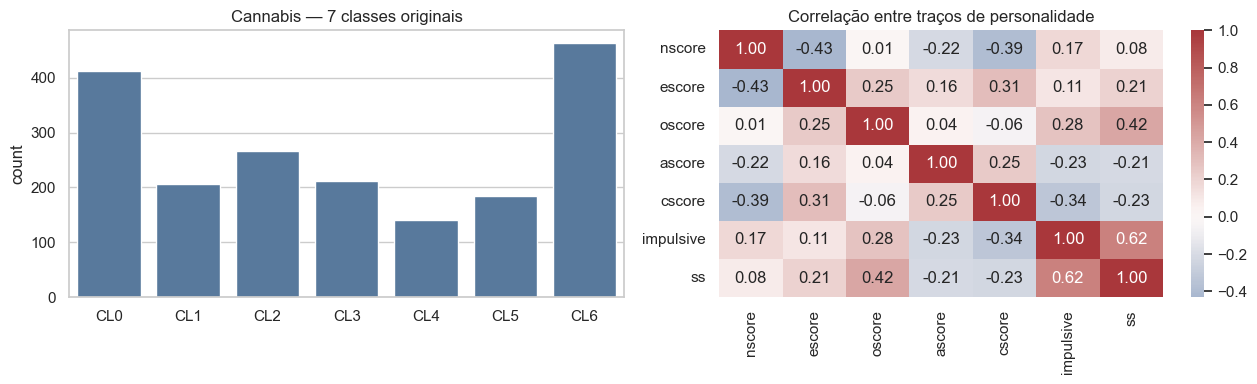

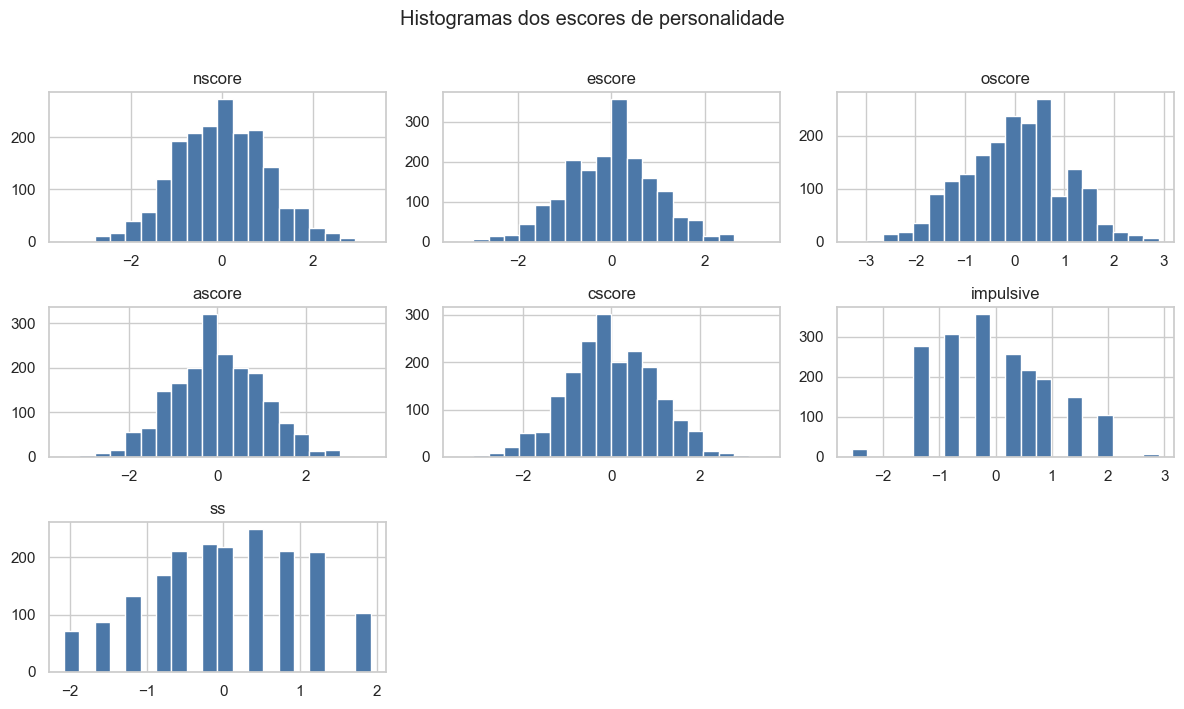

In [23]:
personalidade = ["nscore", "escore", "oscore", "ascore", "cscore", "impulsive", "ss"]

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
ordem = [f"CL{i}" for i in range(7)]
sns.countplot(data=df_bruto, x=ALVO_SUBSTANCIA, order=ordem, ax=eixos[0], color="#4C78A8")
eixos[0].set_title("Cannabis — 7 classes originais")
eixos[0].set_xlabel("")

sns.heatmap(
    df_bruto[personalidade].corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    ax=eixos[1],
)
eixos[1].set_title("Correlação entre traços de personalidade")
plt.tight_layout()
plt.show()

df_bruto[personalidade].hist(bins=20, figsize=(12, 7), color="#4C78A8", edgecolor="white")
plt.suptitle("Histogramas dos escores de personalidade", y=1.01)
plt.tight_layout()
plt.show()

## 3. Transformação nas colunas

1. Decodificar os valores quantificados de idade, gênero, escolaridade, país e etnia para categorias legíveis.
2. Binarizar o alvo (`usuario_cannabis`).
3. Criar `ss_impulsivo` = busca de sensação + impulsividade (marcador de risco conhecido na literatura).
4. No pipeline: *one-hot* das categorias e padronização dos escores.

In [24]:
MAPAS = {
    "age": {
        -0.95197: "18-24",
        -0.07854: "25-34",
        0.49788: "35-44",
        1.09449: "45-54",
        1.82213: "55-64",
        2.59171: "65+",
    },
    "gender": {-0.48246: "masculino", 0.48246: "feminino"},
    "education": {
        -2.43591: "saiu_antes_16",
        -1.73790: "saiu_aos_16",
        -1.43719: "saiu_aos_17",
        -1.22751: "saiu_aos_18",
        -0.61113: "faculdade_incompleta",
        -0.05921: "certificado_profissional",
        0.45468: "graduacao",
        1.16365: "mestrado",
        1.98437: "doutorado",
    },
    "country": {
        -0.57009: "USA",
        -0.46841: "Nova Zelandia",
        -0.28519: "Outro",
        -0.09765: "Australia",
        0.21128: "Irlanda",
        0.24923: "Canada",
        0.96082: "UK",
    },
    "ethnicity": {
        -1.10702: "negra",
        -0.50212: "asiatica",
        -0.31685: "branca",
        -0.22166: "mista_branca_negra",
        0.11440: "outra",
        0.12600: "mista_branca_asiatica",
        1.90725: "mista_negra_asiatica",
    },
}


def decodificar_quantificado(serie: pd.Series, mapa: dict) -> pd.Series:
    chaves = np.array(list(mapa.keys()), dtype=float)
    rotulos = list(mapa.values())

    def _um(valor):
        idx = int(np.argmin(np.abs(chaves - float(valor))))
        return rotulos[idx]

    return serie.map(_um)


df = df_bruto.copy()

for coluna, mapa in MAPAS.items():
    df[coluna] = decodificar_quantificado(df[coluna], mapa)

classes_nao_usuario = {"CL0", "CL1"}
df["usuario_cannabis"] = (
    ~df[ALVO_SUBSTANCIA].astype(str).str.upper().isin(classes_nao_usuario)
).astype(int)

df["ss_impulsivo"] = df["ss"] + df["impulsive"]

print("Categorias decodificadas (amostra):")
display(df[["age", "gender", "education", "country", "ethnicity"]].head())

print("\nAlvo binarizado (0 = não usuário, 1 = usuário):")
display(
    df["usuario_cannabis"]
    .value_counts()
    .rename(index={0: "nao_usuario", 1: "usuario"})
    .to_frame("n")
    .assign(proporcao=lambda d: d["n"] / d["n"].sum())
)

Categorias decodificadas (amostra):


,age,gender,education,country,ethnicity
0,35-44,feminino,certificado_profissional,UK,mista_branca_asiatica
1,25-34,masculino,doutorado,UK,branca
2,35-44,masculino,certificado_profissional,UK,branca
3,18-24,feminino,mestrado,UK,branca
4,35-44,feminino,doutorado,UK,branca



Alvo binarizado (0 = não usuário, 1 = usuário):


,n,proporcao
usuario_cannabis,,
usuario,1265,0.6711
nao_usuario,620,0.3289


C:\Users\mateu\AppData\Local\Temp\ipykernel_26584\2822806459.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  eixos[0].set_xticklabels(["não usuário", "usuário"])
C:\Users\mateu\AppData\Local\Temp\ipykernel_26584\2822806459.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  eixos[2].set_xticklabels(["não usuário", "usuário"])


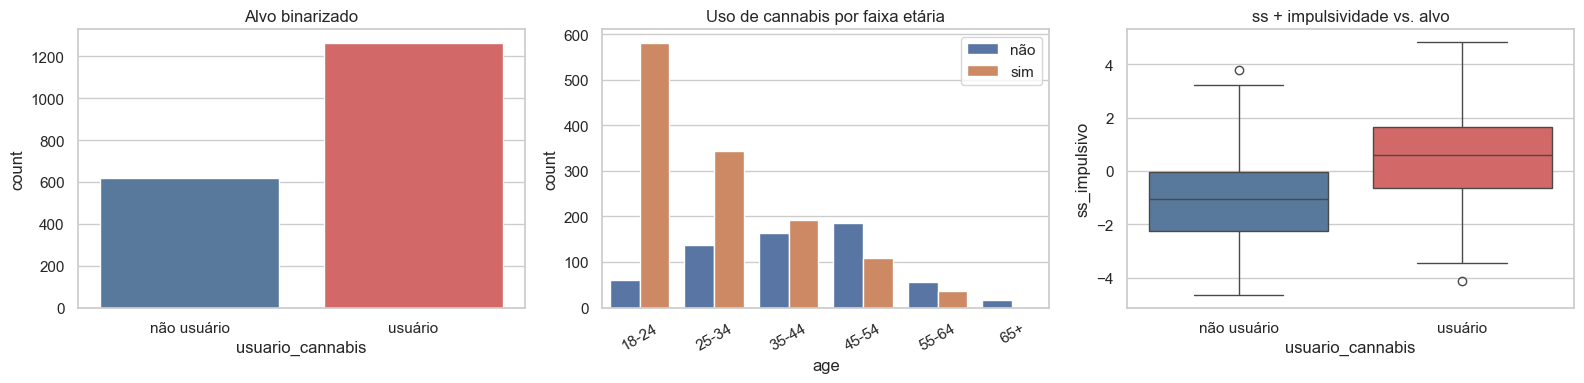

In [25]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, x="usuario_cannabis", ax=eixos[0], palette=["#4C78A8", "#E45756"])
eixos[0].set_xticklabels(["não usuário", "usuário"])
eixos[0].set_title("Alvo binarizado")

sns.countplot(data=df, x="age", hue="usuario_cannabis", ax=eixos[1],
              order=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"])
eixos[1].set_title("Uso de cannabis por faixa etária")
eixos[1].tick_params(axis="x", rotation=30)
eixos[1].legend(title="", labels=["não", "sim"])

sns.boxplot(data=df, x="usuario_cannabis", y="ss_impulsivo", ax=eixos[2],
            palette=["#4C78A8", "#E45756"])
eixos[2].set_xticklabels(["não usuário", "usuário"])
eixos[2].set_title("ss + impulsividade vs. alvo")
plt.tight_layout()
plt.show()

## 4. Transformação nas linhas

1. Remover quem declarou uso de **Semeron** (droga inventada — resposta pouco confiável).
2. Remover duplicatas.
3. Remover outliers extremos de `nscore` (neuroticismo) só na classe majoritária, via IQR × 3.

In [26]:
n0 = len(df)

df = df.loc[df["semer"].astype(str).str.upper().eq("CL0")].copy()
n1 = len(df)

df = df.drop_duplicates()
n2 = len(df)

classe_majoritaria = int(df["usuario_cannabis"].value_counts().idxmax())
serie_maj = df.loc[df["usuario_cannabis"] == classe_majoritaria, "nscore"]
q1, q3 = serie_maj.quantile(0.25), serie_maj.quantile(0.75)
iqr = q3 - q1
lim_inf, lim_sup = q1 - 3 * iqr, q3 + 3 * iqr
outlier_maj = (
    (df["usuario_cannabis"] == classe_majoritaria)
    & ((df["nscore"] < lim_inf) | (df["nscore"] > lim_sup))
)
df = df.loc[~outlier_maj].copy()
n3 = len(df)

display(pd.DataFrame({
    "etapa": ["original", "sem superestimadores (Semeron)", "sem duplicatas", "sem outliers de nscore (classe majoritária)"],
    "linhas": [n0, n1, n2, n3],
}))

,etapa,linhas
0,original,1885
1,sem superestimadores (Semeron),1877
2,sem duplicatas,1877
3,sem outliers de nscore (classe majoritária),1877


In [27]:
alvo = "usuario_cannabis"
drogas = [
    "alcohol", "amphet", "amyl", "benzos", "caff", "cannabis", "choc", "coke",
    "crack", "ecstasy", "heroin", "ketamine", "legalh", "lsd", "meth",
    "mushrooms", "nicotine", "semer", "vsa",
]
colunas_saida = [c for c in drogas + ["id"] if c in df.columns]

X = df.drop(columns=colunas_saida + [alvo])
y = df[alvo].astype(int)

print("Preditoras:", list(X.columns))
print("X:", X.shape, "| y:", y.shape)
display(X.head())

Preditoras: ['age', 'gender', 'education', 'country', 'ethnicity', 'nscore', 'escore', 'oscore', 'ascore', 'cscore', 'impulsive', 'ss', 'ss_impulsivo']
X: (1877, 13) | y: (1877,)


,age,gender,education,country,ethnicity,nscore,escore,oscore,ascore,cscore,impulsive,ss,ss_impulsivo
0,35-44,feminino,certificado_profissional,UK,mista_branca_asiatica,0.3129,-0.5755,-0.5833,-0.9170,-0.0066,-0.2171,-1.1808,-1.3980
1,25-34,masculino,doutorado,UK,branca,-0.6783,1.9389,1.4353,0.7610,-0.1428,-0.7113,-0.2157,-0.9270
2,35-44,masculino,certificado_profissional,UK,branca,-0.4672,0.8052,-0.8473,-1.6209,-1.0145,-1.3798,0.4015,-0.9783
3,18-24,feminino,mestrado,UK,branca,-0.1488,-0.8062,-0.0193,0.5904,0.5849,-1.3798,-1.1808,-2.5607
4,35-44,feminino,doutorado,UK,branca,0.7355,-1.6334,-0.4517,-0.3017,1.3061,-0.2171,-0.2157,-0.4329


## 5. Três subconjuntos: treino, validação e teste

Partição estratificada: **60% treino**, **20% validação**, **20% teste**.

In [28]:
X_treino_val, X_teste, y_treino_val, y_teste = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_treino, X_validacao, y_treino, y_validacao = train_test_split(
    X_treino_val, y_treino_val, test_size=0.25, stratify=y_treino_val, random_state=RANDOM_STATE
)

partes = pd.DataFrame({
    "conjunto": ["treino", "validação", "teste"],
    "linhas": [len(X_treino), len(X_validacao), len(X_teste)],
    "usuarios": [int(y_treino.sum()), int(y_validacao.sum()), int(y_teste.sum())],
    "taxa_usuario": [float(y_treino.mean()), float(y_validacao.mean()), float(y_teste.mean())],
})
partes["proporcao_do_total"] = partes["linhas"] / len(X)
display(partes)

,conjunto,linhas,usuarios,taxa_usuario,proporcao_do_total
0,treino,1125,753,0.6693,0.5994
1,validação,376,252,0.6702,0.2003
2,teste,376,252,0.6702,0.2003


## 6. Treinamento e avaliação

`RandomForestClassifier` com `class_weight="balanced"`. A profundidade máxima é escolhida pelo **F1 da classe usuário** no conjunto de validação.

In [29]:
colunas_categoricas = ["age", "gender", "education", "country", "ethnicity"]
colunas_numericas = [c for c in X.columns if c not in colunas_categoricas]

preprocessador = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), colunas_categoricas),
        ("num", StandardScaler(), colunas_numericas),
    ]
)

resultados_val = []
for profundidade in [4, 6, 8, 10, 12, None]:
    pipe = Pipeline([
        ("prep", preprocessador),
        ("modelo", RandomForestClassifier(
            n_estimators=300,
            max_depth=profundidade,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ])
    pipe.fit(X_treino, y_treino)
    pred_val = pipe.predict(X_validacao)
    proba_val = pipe.predict_proba(X_validacao)[:, 1]
    resultados_val.append({
        "max_depth": profundidade if profundidade is not None else "livre",
        "acuracia_val": accuracy_score(y_validacao, pred_val),
        "f1_usuario_val": f1_score(y_validacao, pred_val, pos_label=1),
        "auc_val": roc_auc_score(y_validacao, proba_val),
        "pipeline": pipe,
    })

display(pd.DataFrame(resultados_val).drop(columns="pipeline"))
melhor = max(resultados_val, key=lambda r: r["f1_usuario_val"])
print("Melhor max_depth na validação:", melhor["max_depth"], "| F1:", round(melhor["f1_usuario_val"], 3))

,max_depth,acuracia_val,f1_usuario_val,auc_val
0,4,0.8059,0.8470,0.9047
1,6,0.8191,0.8601,0.9105
2,8,0.8378,0.8782,0.9135
3,10,0.8457,0.8854,0.9147
4,12,0.8378,0.8820,0.9143
5,livre,0.8484,0.8918,0.9162


Melhor max_depth na validação: livre | F1: 0.892


In [30]:
melhor_depth = None if melhor["max_depth"] == "livre" else melhor["max_depth"]

pipeline_final = Pipeline([
    ("prep", preprocessador),
    ("modelo", RandomForestClassifier(
        n_estimators=300,
        max_depth=melhor_depth,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])
pipeline_final.fit(X_treino_val, y_treino_val)

y_pred = pipeline_final.predict(X_teste)
y_proba = pipeline_final.predict_proba(X_teste)[:, 1]

print("Relatório no TESTE:")
print(classification_report(y_teste, y_pred, target_names=["não usuário", "usuário"]))
print("ROC-AUC (teste):", round(roc_auc_score(y_teste, y_proba), 4))

Relatório no TESTE:
              precision    recall  f1-score   support

 não usuário       0.69      0.61      0.65       124
     usuário       0.82      0.87      0.84       252

    accuracy                           0.78       376
   macro avg       0.76      0.74      0.75       376
weighted avg       0.78      0.78      0.78       376

ROC-AUC (teste): 0.8519


## 7. Matriz de confusão e acurácia

Acurácia no teste: 0.7819 (78.19%)
VN=76 | FP=48 | FN=34 | VP=218


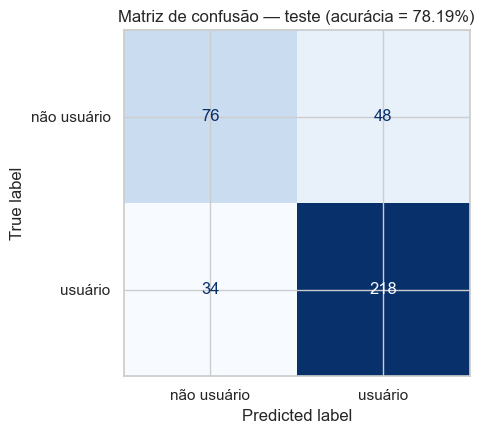

In [31]:
acuracia = accuracy_score(y_teste, y_pred)
matriz = confusion_matrix(y_teste, y_pred)
vn, fp, fn, vp = matriz.ravel()

print(f"Acurácia no teste: {acuracia:.4f} ({acuracia:.2%})")
print(f"VN={vn} | FP={fp} | FN={fn} | VP={vp}")

fig, eixo = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["não usuário", "usuário"],
).plot(cmap="Blues", ax=eixo, colorbar=False)
eixo.set_title(f"Matriz de confusão — teste (acurácia = {acuracia:.2%})")
plt.tight_layout()
plt.show()

## 8. Implantação e uma predição do modelo implantado

O pipeline (pré-processamento + floresta) é gravado em disco e **recarregado** para a predição, como em produção.

In [32]:
caminho_modelo = PASTA_ARTEFATOS / "modelo_cannabis.joblib"
caminho_schema = PASTA_ARTEFATOS / "schema_entrada.json"

joblib.dump(pipeline_final, caminho_modelo)
caminho_schema.write_text(
    json.dumps(
        {"colunas": list(X.columns), "alvo": alvo, "classes": {"0": "nao_usuario", "1": "usuario"}},
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)
print("Modelo:", caminho_modelo.resolve())
print("Schema:", caminho_schema.resolve())

Modelo: C:\laragon\www\Projetos Fatec\Trabalho-Bimestral_IA\artefatos\modelo_cannabis.joblib
Schema: C:\laragon\www\Projetos Fatec\Trabalho-Bimestral_IA\artefatos\schema_entrada.json


In [33]:
modelo_implantado = joblib.load(caminho_modelo)

amostra_real = X_teste.iloc[[0]]
rotulo_real = int(y_teste.iloc[0])
pred_real = int(modelo_implantado.predict(amostra_real)[0])
proba_real = float(modelo_implantado.predict_proba(amostra_real)[0, 1])

print("--- Caso do conjunto de teste ---")
display(amostra_real)
print(f"Rótulo real: {rotulo_real} | Predito: {pred_real} | P(usuário) = {proba_real:.3f}")

perfil_novo = pd.DataFrame([{
    "age": "18-24",
    "gender": "masculino",
    "education": "faculdade_incompleta",
    "country": "USA",
    "ethnicity": "branca",
    "nscore": 0.4,
    "escore": 0.8,
    "oscore": 1.2,
    "ascore": -0.3,
    "cscore": -0.9,
    "impulsive": 1.29,
    "ss": 1.22,
    "ss_impulsivo": 1.29 + 1.22,
}])

classe_nova = int(modelo_implantado.predict(perfil_novo)[0])
prob_nova = float(modelo_implantado.predict_proba(perfil_novo)[0, 1])
rotulo_novo = "usuário" if classe_nova == 1 else "não usuário"

print("\n--- Perfil novo (modelo recarregado do disco) ---")
display(perfil_novo)
print(f"Classe prevista: {classe_nova} ({rotulo_novo})")
print(f"Probabilidade de ser usuário: {prob_nova:.3f}")

--- Caso do conjunto de teste ---


,age,gender,education,country,ethnicity,nscore,escore,oscore,ascore,cscore,impulsive,ss,ss_impulsivo
787,18-24,masculino,graduacao,Australia,branca,-0.1488,-0.4400,0.8831,-0.6063,-0.7815,1.2922,0.7654,2.0576


Rótulo real: 1 | Predito: 1 | P(usuário) = 0.963

--- Perfil novo (modelo recarregado do disco) ---


,age,gender,education,country,ethnicity,nscore,escore,oscore,ascore,cscore,impulsive,ss,ss_impulsivo
0,18-24,masculino,faculdade_incompleta,USA,branca,0.4000,0.8000,1.2000,-0.3000,-0.9000,1.2900,1.2200,2.5100


Classe prevista: 1 (usuário)
Probabilidade de ser usuário: 0.990


## 9. Conclusão

A esteira carregou a base 373, descreveu os dados, decodificou colunas quantificadas, limpou linhas (Semeron, duplicatas, outliers), separou treino/validação/teste, treinou uma floresta aleatória e avaliou no teste com matriz de confusão e acurácia. A última célula consome o `.joblib` implantado.

**Referência:** Fehrman, E., Egan, V., & Mirkes, E. (2015). Drug Consumption (Quantified). UCI Machine Learning Repository. https://doi.org/10.24432/C5TC7S